In [2]:
import pandas as pd
from scipy.io import arff
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.model_selection import train_test_split

data, meta = arff.loadarff("../data/Training Dataset.arff")
df = pd.DataFrame(data)

for column in df.columns:
    if df[column].dtype == "object":
        df[column] = df[column].str.decode("utf-8").astype(int)

X = df.drop(columns="Result")
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8844, 30)
Testing: (2211, 30)


In [3]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Importance
0,SSLfinal_State,0.319667
1,URL_of_Anchor,0.250049
2,web_traffic,0.070803
3,having_Sub_Domain,0.069482
4,Links_in_tags,0.043887
5,Prefix_Suffix,0.037888
6,SFH,0.020226
7,Links_pointing_to_page,0.019292
8,Request_URL,0.017682
9,Domain_registeration_length,0.016681


In [23]:
top_10_features = feature_importance.head(10).copy()

top_10_features

,Feature,Importance
0,SSLfinal_State,0.319667
1,URL_of_Anchor,0.250049
2,web_traffic,0.070803
3,having_Sub_Domain,0.069482
4,Links_in_tags,0.043887
5,Prefix_Suffix,0.037888
6,SFH,0.020226
7,Links_pointing_to_page,0.019292
8,Request_URL,0.017682
9,Domain_registeration_length,0.016681


## Feature Selection and Reduction

The baseline experiments used all 30 available input features. However, using every available feature may introduce redundant information and increase the dimensionality of the input data.

The objective of this stage is to investigate whether a smaller subset of features can maintain similar classification performance.

Random Forest feature importance is used to rank the input features according to their contribution to the trained model. Based on this ranking, subsets containing the top 30, 20, 15, and 10 features are evaluated.

The performance of the reduced feature sets is compared with the 30-feature baseline using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

In [4]:
feature_sets = {
    30: feature_importance["Feature"].head(30).tolist(),
    20: feature_importance["Feature"].head(20).tolist(),
    15: feature_importance["Feature"].head(15).tolist(),
    10: feature_importance["Feature"].head(10).tolist()
}

for n_features, features in feature_sets.items():
    print(f"{n_features} features:")
    print(features)
    print()

30 features:
['SSLfinal_State', 'URL_of_Anchor', 'web_traffic', 'having_Sub_Domain', 'Links_in_tags', 'Prefix_Suffix', 'SFH', 'Links_pointing_to_page', 'Request_URL', 'Domain_registeration_length', 'age_of_domain', 'Google_Index', 'having_IP_Address', 'DNSRecord', 'Page_Rank', 'URL_Length', 'HTTPS_token', 'Redirect', 'Submitting_to_email', 'having_At_Symbol', 'Statistical_report', 'Shortining_Service', 'popUpWidnow', 'Favicon', 'Abnormal_URL', 'double_slash_redirecting', 'on_mouseover', 'Iframe', 'port', 'RightClick']

20 features:
['SSLfinal_State', 'URL_of_Anchor', 'web_traffic', 'having_Sub_Domain', 'Links_in_tags', 'Prefix_Suffix', 'SFH', 'Links_pointing_to_page', 'Request_URL', 'Domain_registeration_length', 'age_of_domain', 'Google_Index', 'having_IP_Address', 'DNSRecord', 'Page_Rank', 'URL_Length', 'HTTPS_token', 'Redirect', 'Submitting_to_email', 'having_At_Symbol']

15 features:
['SSLfinal_State', 'URL_of_Anchor', 'web_traffic', 'having_Sub_Domain', 'Links_in_tags', 'Prefix_Su

In [5]:
selected_features = feature_sets[20]

X_train_20 = X_train[selected_features]
X_test_20 = X_test[selected_features]

rf_20 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_20.fit(X_train_20, y_train)

rf_20_predictions = rf_20.predict(X_test_20)
rf_20_probabilities = rf_20.predict_proba(X_test_20)[:, 1]

rf_20_accuracy = accuracy_score(y_test, rf_20_predictions)
rf_20_precision = precision_score(y_test, rf_20_predictions, pos_label=1)
rf_20_recall = recall_score(y_test, rf_20_predictions, pos_label=1)
rf_20_f1 = f1_score(y_test, rf_20_predictions, pos_label=1)
rf_20_auc = roc_auc_score(y_test, rf_20_probabilities)

print(f"20 Features - Random Forest")
print(f"Accuracy : {rf_20_accuracy:.4f}")
print(f"Precision: {rf_20_precision:.4f}")
print(f"Recall   : {rf_20_recall:.4f}")
print(f"F1-score : {rf_20_f1:.4f}")
print(f"ROC-AUC  : {rf_20_auc:.4f}")

20 Features - Random Forest
Accuracy : 0.9738
Precision: 0.9703
Recall   : 0.9829
F1-score : 0.9766
ROC-AUC  : 0.9975


### Feature Importance using Random Forest

A Random Forest classifier is trained on the complete training set to estimate the relative importance of each input feature.

The resulting importance scores are used to rank the 30 features from highest to lowest importance. These rankings are then used to construct the reduced feature subsets.

In [6]:
selected_features = feature_sets[15]

X_train_15 = X_train[selected_features]
X_test_15 = X_test[selected_features]

rf_15 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_15.fit(X_train_15, y_train)

rf_15_predictions = rf_15.predict(X_test_15)
rf_15_probabilities = rf_15.predict_proba(X_test_15)[:, 1]

rf_15_accuracy = accuracy_score(y_test, rf_15_predictions)
rf_15_precision = precision_score(y_test, rf_15_predictions, pos_label=1)
rf_15_recall = recall_score(y_test, rf_15_predictions, pos_label=1)
rf_15_f1 = f1_score(y_test, rf_15_predictions, pos_label=1)
rf_15_auc = roc_auc_score(y_test, rf_15_probabilities)

print("15 Features - Random Forest")
print(f"Accuracy : {rf_15_accuracy:.4f}")
print(f"Precision: {rf_15_precision:.4f}")
print(f"Recall   : {rf_15_recall:.4f}")
print(f"F1-score : {rf_15_f1:.4f}")
print(f"ROC-AUC  : {rf_15_auc:.4f}")

15 Features - Random Forest
Accuracy : 0.9701
Precision: 0.9649
Recall   : 0.9821
F1-score : 0.9734
ROC-AUC  : 0.9965


### Evaluation of Reduced Feature Sets

The top-ranked features are evaluated using Random Forest classification.

Four feature-set sizes are considered:

- 30 features: complete feature set and baseline
- 20 features: moderate reduction
- 15 features: 50% reduction
- 10 features: substantial reduction

The same training/testing split and Random Forest configuration are used for each experiment to make the comparison consistent.

In [7]:
selected_features = feature_sets[10]

X_train_10 = X_train[selected_features]
X_test_10 = X_test[selected_features]

rf_10 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_10.fit(X_train_10, y_train)

rf_10_predictions = rf_10.predict(X_test_10)
rf_10_probabilities = rf_10.predict_proba(X_test_10)[:, 1]

rf_10_accuracy = accuracy_score(y_test, rf_10_predictions)
rf_10_precision = precision_score(y_test, rf_10_predictions, pos_label=1)
rf_10_recall = recall_score(y_test, rf_10_predictions, pos_label=1)
rf_10_f1 = f1_score(y_test, rf_10_predictions, pos_label=1)
rf_10_auc = roc_auc_score(y_test, rf_10_probabilities)

print("10 Features - Random Forest")
print(f"Accuracy : {rf_10_accuracy:.4f}")
print(f"Precision: {rf_10_precision:.4f}")
print(f"Recall   : {rf_10_recall:.4f}")
print(f"F1-score : {rf_10_f1:.4f}")
print(f"ROC-AUC  : {rf_10_auc:.4f}")

10 Features - Random Forest
Accuracy : 0.9516
Precision: 0.9467
Recall   : 0.9675
F1-score : 0.9570
ROC-AUC  : 0.9893


### Feature Reduction Results

The Random Forest classifier was evaluated using four feature-set sizes: 30, 20, 15, and 10 features.

The results show that reducing the feature set from 30 to 20 features causes only a very small change in predictive performance. The 20-feature model achieves 97.38% accuracy and 97.66% F1-score compared with 97.42% accuracy and 97.70% F1-score for the full 30-feature model.

Further reduction to 15 features results in a somewhat larger performance decrease, while reducing the feature set to 10 features produces a more noticeable decline.

These results indicate that moderate feature reduction may retain most of the predictive information in the original feature set, while aggressive feature reduction can negatively affect classification performance.

results_rf_reduction = pd.DataFrame({
    "Features": [30, 20, 15, 10],
    "Reduction_Percentage": [0, 33.3, 50.0, 66.7],
    "Accuracy": [
        0.9742,
        rf_20_accuracy,
        rf_15_accuracy,
        rf_10_accuracy
    ],
    "Precision": [
        0.9696,
        rf_20_precision,
        rf_15_precision,
        rf_10_precision
    ],
    "Recall": [
        0.9846,
        rf_20_recall,
        rf_15_recall,
        rf_10_recall
    ],
    "F1_Score": [
        0.9770,
        rf_20_f1,
        rf_15_f1,
        rf_10_f1
    ],
    "ROC_AUC": [
        0.9977,
        rf_20_auc,
        rf_15_auc,
        rf_10_auc
    ]
})

results_rf_reduction

In [8]:
results_rf_reduction = pd.DataFrame({
    "Features": [30, 20, 15, 10],
    "Reduction_Percentage": [0, 33.3, 50.0, 66.7],
    "Accuracy": [
        0.9742,
        rf_20_accuracy,
        rf_15_accuracy,
        rf_10_accuracy
    ],
    "Precision": [
        0.9696,
        rf_20_precision,
        rf_15_precision,
        rf_10_precision
    ],
    "Recall": [
        0.9846,
        rf_20_recall,
        rf_15_recall,
        rf_10_recall
    ],
    "F1_Score": [
        0.9770,
        rf_20_f1,
        rf_15_f1,
        rf_10_f1
    ],
    "ROC_AUC": [
        0.9977,
        rf_20_auc,
        rf_15_auc,
        rf_10_auc
    ]
})

results_rf_reduction

,Features,Reduction_Percentage,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,30,0.0,0.974200,0.969600,0.984600,0.977000,0.997700
1,20,33.3,0.973768,0.970329,0.982941,0.976594,0.997500
2,15,50.0,0.970149,0.964884,0.982128,0.973430,0.996498
3,10,66.7,0.951606,0.946741,0.967506,0.957011,0.989297


In [9]:
results_rf_reduction.to_csv(
    "../results/tables/random_forest_feature_reduction.csv",
    index=False
)

print("Feature reduction results saved successfully.")

Feature reduction results saved successfully.


### Performance vs. Number of Features

The following visualization shows how Random Forest performance changes as the number of input features is reduced. The comparison helps illustrate the trade-off between dimensionality reduction and predictive performance.

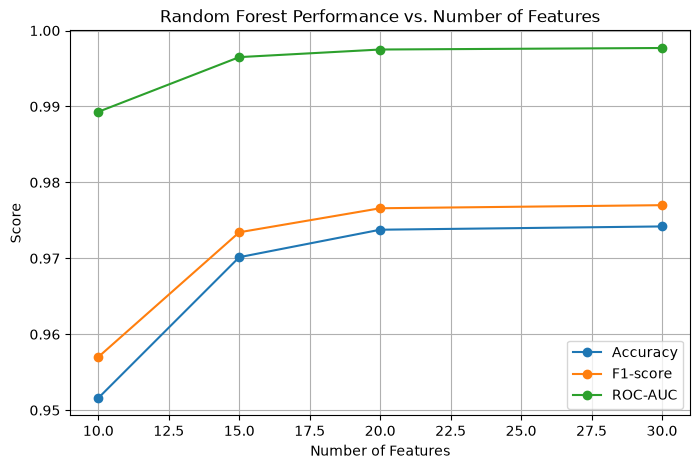

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_rf_reduction["Features"],
    results_rf_reduction["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_rf_reduction["Features"],
    results_rf_reduction["F1_Score"],
    marker="o",
    label="F1-score"
)

plt.plot(
    results_rf_reduction["Features"],
    results_rf_reduction["ROC_AUC"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel("Number of Features")
plt.ylabel("Score")
plt.title("Random Forest Performance vs. Number of Features")
plt.legend()
plt.grid(True)
plt.show()

### Observation: Performance vs. Number of Features

The performance of the Random Forest classifier remains relatively stable when the number of features is reduced from 30 to 20. The 20-feature model achieves performance very close to that of the complete 30-feature model.

A further reduction to 15 features results in a small decrease in performance, while reducing the feature set to 10 features causes a more noticeable decline across the evaluation metrics.

These results suggest that moderate feature reduction can retain most of the predictive information while substantially reducing the number of input features. However, aggressive reduction may remove useful information and negatively affect classification performance.

In [11]:
from sklearn.tree import DecisionTreeClassifier

dt_results = []

for n in [20, 15, 10]:
    selected_features = feature_sets[n]

    X_train_n = X_train[selected_features]
    X_test_n = X_test[selected_features]

    dt_model = DecisionTreeClassifier(random_state=42)
    dt_model.fit(X_train_n, y_train)

    y_pred = dt_model.predict(X_test_n)
    y_prob = dt_model.predict_proba(X_test_n)[:, 1]

    dt_results.append({
        "Features": n,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),
        "Recall": recall_score(y_test, y_pred, pos_label=1),
        "F1_Score": f1_score(y_test, y_pred, pos_label=1),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

dt_results_df = pd.DataFrame(dt_results)

dt_results_df

,Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,20,0.970602,0.968650,0.978879,0.973737,0.979875
1,15,0.965626,0.966102,0.972380,0.969231,0.979025
2,10,0.949344,0.948677,0.961007,0.954802,0.986593


In [12]:
dt_results_df.to_csv(
    "../results/tables/decision_tree_feature_reduction.csv",
    index=False
)

print("Decision Tree feature-reduction results saved.")

Decision Tree feature-reduction results saved.


In [13]:
from sklearn.ensemble import GradientBoostingClassifier

gb_results = []

for n in [20, 15, 10]:
    selected_features = feature_sets[n]

    X_train_n = X_train[selected_features]
    X_test_n = X_test[selected_features]

    gb_model = GradientBoostingClassifier(random_state=42)
    gb_model.fit(X_train_n, y_train)

    y_pred = gb_model.predict(X_test_n)
    y_prob = gb_model.predict_proba(X_test_n)[:, 1]

    gb_results.append({
        "Features": n,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),
        "Recall": recall_score(y_test, y_pred, pos_label=1),
        "F1_Score": f1_score(y_test, y_pred, pos_label=1),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

gb_results_df = pd.DataFrame(gb_results)

gb_results_df

,Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,20,0.952510,0.951122,0.964257,0.957644,0.991653
1,15,0.953415,0.952648,0.964257,0.958417,0.991283
2,10,0.943464,0.943820,0.955321,0.949536,0.988931


In [14]:
gb_results_df.to_csv(
    "../results/tables/gradient_boosting_feature_reduction.csv",
    index=False
)

print("Gradient Boosting feature-reduction results saved.")


Gradient Boosting feature-reduction results saved.


In [15]:
dt_results_df["Reduction_Percentage"] = (
    (30 - dt_results_df["Features"]) / 30 * 100
).round(1)

gb_results_df["Reduction_Percentage"] = (
    (30 - gb_results_df["Features"]) / 30 * 100
).round(1)

dt_results_df

,Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Reduction_Percentage
0,20,0.970602,0.968650,0.978879,0.973737,0.979875,33.3
1,15,0.965626,0.966102,0.972380,0.969231,0.979025,50.0
2,10,0.949344,0.948677,0.961007,0.954802,0.986593,66.7


In [16]:
gb_results_df["Reduction_Percentage"] = (
    (30 - gb_results_df["Features"]) / 30 * 100
).round(1)

gb_results_df

,Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Reduction_Percentage
0,20,0.952510,0.951122,0.964257,0.957644,0.991653,33.3
1,15,0.953415,0.952648,0.964257,0.958417,0.991283,50.0
2,10,0.943464,0.943820,0.955321,0.949536,0.988931,66.7


In [17]:
rf_results_df["Model"] = "Random Forest"

combined_reduction_results = pd.concat(
    [
        rf_results_df,
        dt_results_df,
        gb_results_df
    ],
    ignore_index=True
)

combined_reduction_results = combined_reduction_results[
    [
        "Model",
        "Features",
        "Reduction_Percentage",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]
]

combined_reduction_results

NameError: name 'rf_results_df' is not defined

In [ ]:
combined_reduction_results.to_csv(
    "../results/tables/combined_feature_reduction_results.csv",
    index=False
)

print("Combined feature-reduction results saved.")

Combined feature-reduction results saved.


### Cross-Model Feature Reduction Comparison

The feature-reduction experiments were performed using Random Forest, Decision Tree, and Gradient Boosting classifiers. The following visualization compares their F1-scores across different numbers of input features.

F1-score is used here because it provides a balance between precision and recall and is therefore useful for evaluating the classification performance of the models.

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for model in combined_reduction_results["Model"].unique():
    model_data = combined_reduction_results[
        combined_reduction_results["Model"] == model
    ].sort_values("Features")

    plt.plot(
        model_data["Features"],
        model_data["F1_Score"],
        marker="o",
        label=model
    )

plt.xlabel("Number of Features")
plt.ylabel("F1-score")
plt.title("F1-score vs. Number of Features")
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'combined_reduction_results' is not defined

<Figure size 800x500 with 0 Axes>

In [18]:
import pandas as pd

rf_results_df = pd.read_csv(
    "../results/tables/random_forest_feature_reduction.csv"
)

dt_results_df = pd.read_csv(
    "../results/tables/decision_tree_feature_reduction.csv"
)

gb_results_df = pd.read_csv(
    "../results/tables/gradient_boosting_feature_reduction.csv"
)

print("RF:", rf_results_df.shape)
print("DT:", dt_results_df.shape)
print("GB:", gb_results_df.shape)

RF: (4, 7)
DT: (3, 6)
GB: (3, 6)


In [19]:
rf_results_df["Model"] = "Random Forest"
dt_results_df["Model"] = "Decision Tree"
gb_results_df["Model"] = "Gradient Boosting"

combined_reduction_results = pd.concat(
    [
        rf_results_df,
        dt_results_df,
        gb_results_df
    ],
    ignore_index=True
)

combined_reduction_results = combined_reduction_results[
    [
        "Model",
        "Features",
        "Reduction_Percentage",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]
]

combined_reduction_results

,Model,Features,Reduction_Percentage,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,30,0.0,0.974200,0.969600,0.984600,0.977000,0.997700
1,Random Forest,20,33.3,0.973768,0.970329,0.982941,0.976594,0.997500
2,Random Forest,15,50.0,0.970149,0.964884,0.982128,0.973430,0.996498
3,Random Forest,10,66.7,0.951606,0.946741,0.967506,0.957011,0.989297
4,Decision Tree,20,NaN,0.970602,0.968650,0.978879,0.973737,0.979875
5,Decision Tree,15,NaN,0.965626,0.966102,0.972380,0.969231,0.979025
6,Decision Tree,10,NaN,0.949344,0.948677,0.961007,0.954802,0.986593
7,Gradient Boosting,20,NaN,0.952510,0.951122,0.964257,0.957644,0.991653
8,Gradient Boosting,15,NaN,0.953415,0.952648,0.964257,0.958417,0.991283
9,Gradient Boosting,10,NaN,0.943464,0.943820,0.955321,0.949536,0.988931


In [20]:
dt_results_df["Reduction_Percentage"] = (
    (30 - dt_results_df["Features"]) / 30 * 100
).round(1)

gb_results_df["Reduction_Percentage"] = (
    (30 - gb_results_df["Features"]) / 30 * 100
).round(1)

combined_reduction_results = pd.concat(
    [
        rf_results_df,
        dt_results_df,
        gb_results_df
    ],
    ignore_index=True
)

combined_reduction_results = combined_reduction_results[
    [
        "Model",
        "Features",
        "Reduction_Percentage",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]
]

combined_reduction_results

,Model,Features,Reduction_Percentage,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,30,0.0,0.974200,0.969600,0.984600,0.977000,0.997700
1,Random Forest,20,33.3,0.973768,0.970329,0.982941,0.976594,0.997500
2,Random Forest,15,50.0,0.970149,0.964884,0.982128,0.973430,0.996498
3,Random Forest,10,66.7,0.951606,0.946741,0.967506,0.957011,0.989297
4,Decision Tree,20,33.3,0.970602,0.968650,0.978879,0.973737,0.979875
5,Decision Tree,15,50.0,0.965626,0.966102,0.972380,0.969231,0.979025
6,Decision Tree,10,66.7,0.949344,0.948677,0.961007,0.954802,0.986593
7,Gradient Boosting,20,33.3,0.952510,0.951122,0.964257,0.957644,0.991653
8,Gradient Boosting,15,50.0,0.953415,0.952648,0.964257,0.958417,0.991283
9,Gradient Boosting,10,66.7,0.943464,0.943820,0.955321,0.949536,0.988931


In [21]:
combined_reduction_results.to_csv(
    "../results/tables/combined_feature_reduction_results.csv",
    index=False
)

print("Corrected combined feature-reduction results saved.")

Corrected combined feature-reduction results saved.


### Cross-Model Feature Reduction Comparison

The feature-reduction experiments were performed using Random Forest, Decision Tree, and Gradient Boosting classifiers. The following visualization compares their F1-scores across different numbers of input features.

F1-score is used here because it provides a balance between precision and recall and is therefore useful for evaluating the classification performance of the models.

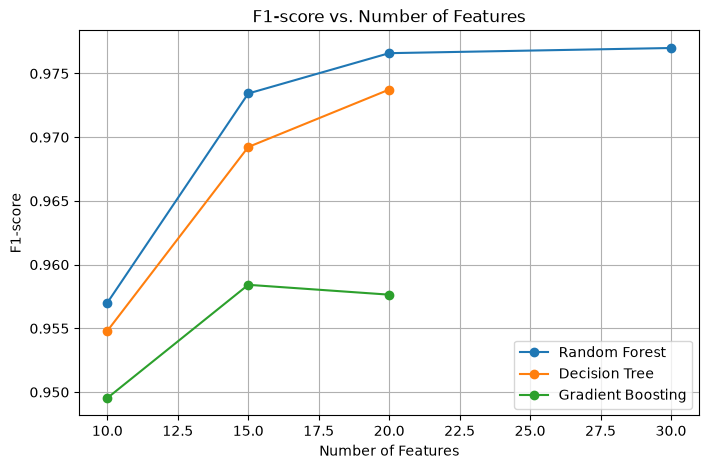

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for model in combined_reduction_results["Model"].unique():
    model_data = combined_reduction_results[
        combined_reduction_results["Model"] == model
    ].sort_values("Features")

    plt.plot(
        model_data["Features"],
        model_data["F1_Score"],
        marker="o",
        label=model
    )

plt.xlabel("Number of Features")
plt.ylabel("F1-score")
plt.title("F1-score vs. Number of Features")
plt.legend()
plt.grid(True)
plt.show()

### Observation: Cross-Model Feature Reduction

The cross-model comparison shows that Random Forest maintains a high F1-score when the feature set is reduced from 30 to 20 features. Decision Tree also maintains a high F1-score with 20 and 15 features, while Gradient Boosting shows lower F1-scores across the evaluated feature subsets.

For all three classifiers, reducing the feature set to 10 features results in a noticeable decrease in F1-score. This suggests that aggressive feature reduction may remove useful predictive information.

Overall, the results indicate that moderate feature reduction can retain most of the classification performance while using fewer input features. The effect of feature reduction, however, varies across machine learning models.

In [24]:
top_10_features.to_csv(
    "../results/tables/top_10_feature_importance.csv",
    index=False
)

print("Top 10 feature importance table saved.")

Top 10 feature importance table saved.
